In [31]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.ticker import AutoMinorLocator

BASE = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

PASTA_MLP = BASE / "mlp_depth_2706/results/burgers/pinn_mlp_depth_4"
PASTA_MPC = BASE / "mpc_serial"

CORES = {
    "MLP": "#000000",
    "MPC": "#C00000",
}

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.0,
    "axes.edgecolor": "black",
    "axes.spines.top": True,
    "axes.spines.right": True,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 130,
    "savefig.dpi": 300,
})

In [32]:
def carregar_resultados(arquivos):
    metricas = []
    historicos = []

    for arquivo in sorted(arquivos):
        with open(arquivo) as f:
            m = json.load(f)

        seed = int(arquivo.parent.name.split("_")[-1])

        m["seed"] = seed
        m["arquivo"] = str(arquivo)
        metricas.append(m)

        h = pd.read_csv(arquivo.parent / "history.csv")
        h["seed"] = seed
        h["arquivo"] = str(arquivo)
        historicos.append(h)

    return (
        pd.DataFrame(metricas),
        pd.concat(historicos, ignore_index=True)
    )


# MLP convencional
metricas_mlp, hist_mlp = carregar_resultados(
    PASTA_MLP.glob("seed_*/metrics.json")
)

# MPC quântico: 5 qubits, 3 camadas, Z, polinomial
metricas_mpc, hist_mpc = carregar_resultados(
    PASTA_MPC.glob(
        "0*_*/q5_l3_z_polynomial/seed_*/metrics.json"
    )
)

# Remover registros repetidos entre etapas
metricas_mpc = metricas_mpc.drop_duplicates("seed")

hist_mpc = hist_mpc[
    hist_mpc["arquivo"].isin(metricas_mpc["arquivo"])
].copy()

print("MLP:", metricas_mlp["seed"].nunique(), "sementes")
print("MPC:", metricas_mpc["seed"].nunique(), "sementes")

MLP: 10 sementes
MPC: 10 sementes


In [33]:
hist_mlp["modelo"] = "MLP"
hist_mpc["modelo"] = "MPC"

historicos = pd.concat(
    [hist_mlp, hist_mpc],
    ignore_index=True
)

def plot_media_intervalo(ax, coluna, titulo, ylabel):
    for modelo in ["MLP", "MPC"]:
        dados = (
            historicos[historicos["modelo"] == modelo]
            .groupby("epoch")[coluna]
            .agg(["mean", "min", "max"])
            .reset_index()
        )

        x = dados["epoch"].to_numpy()

        ax.plot(
            x,
            dados["mean"].to_numpy(),
            color=CORES[modelo],
            linewidth=2.0,
            label=modelo
        )

        ax.fill_between(
            x,
            dados["min"].to_numpy(),
            dados["max"].to_numpy(),
            color=CORES[modelo],
            alpha=0.12,
            linewidth=0
        )

    #ax.set_title(titulo, pad=12)
    ax.set_xlabel("Epoch", fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_yscale("log")
    ax.grid(True)
    ax.legend(loc="best")
    ax.tick_params(which="both", direction="in", top=True, right=True)

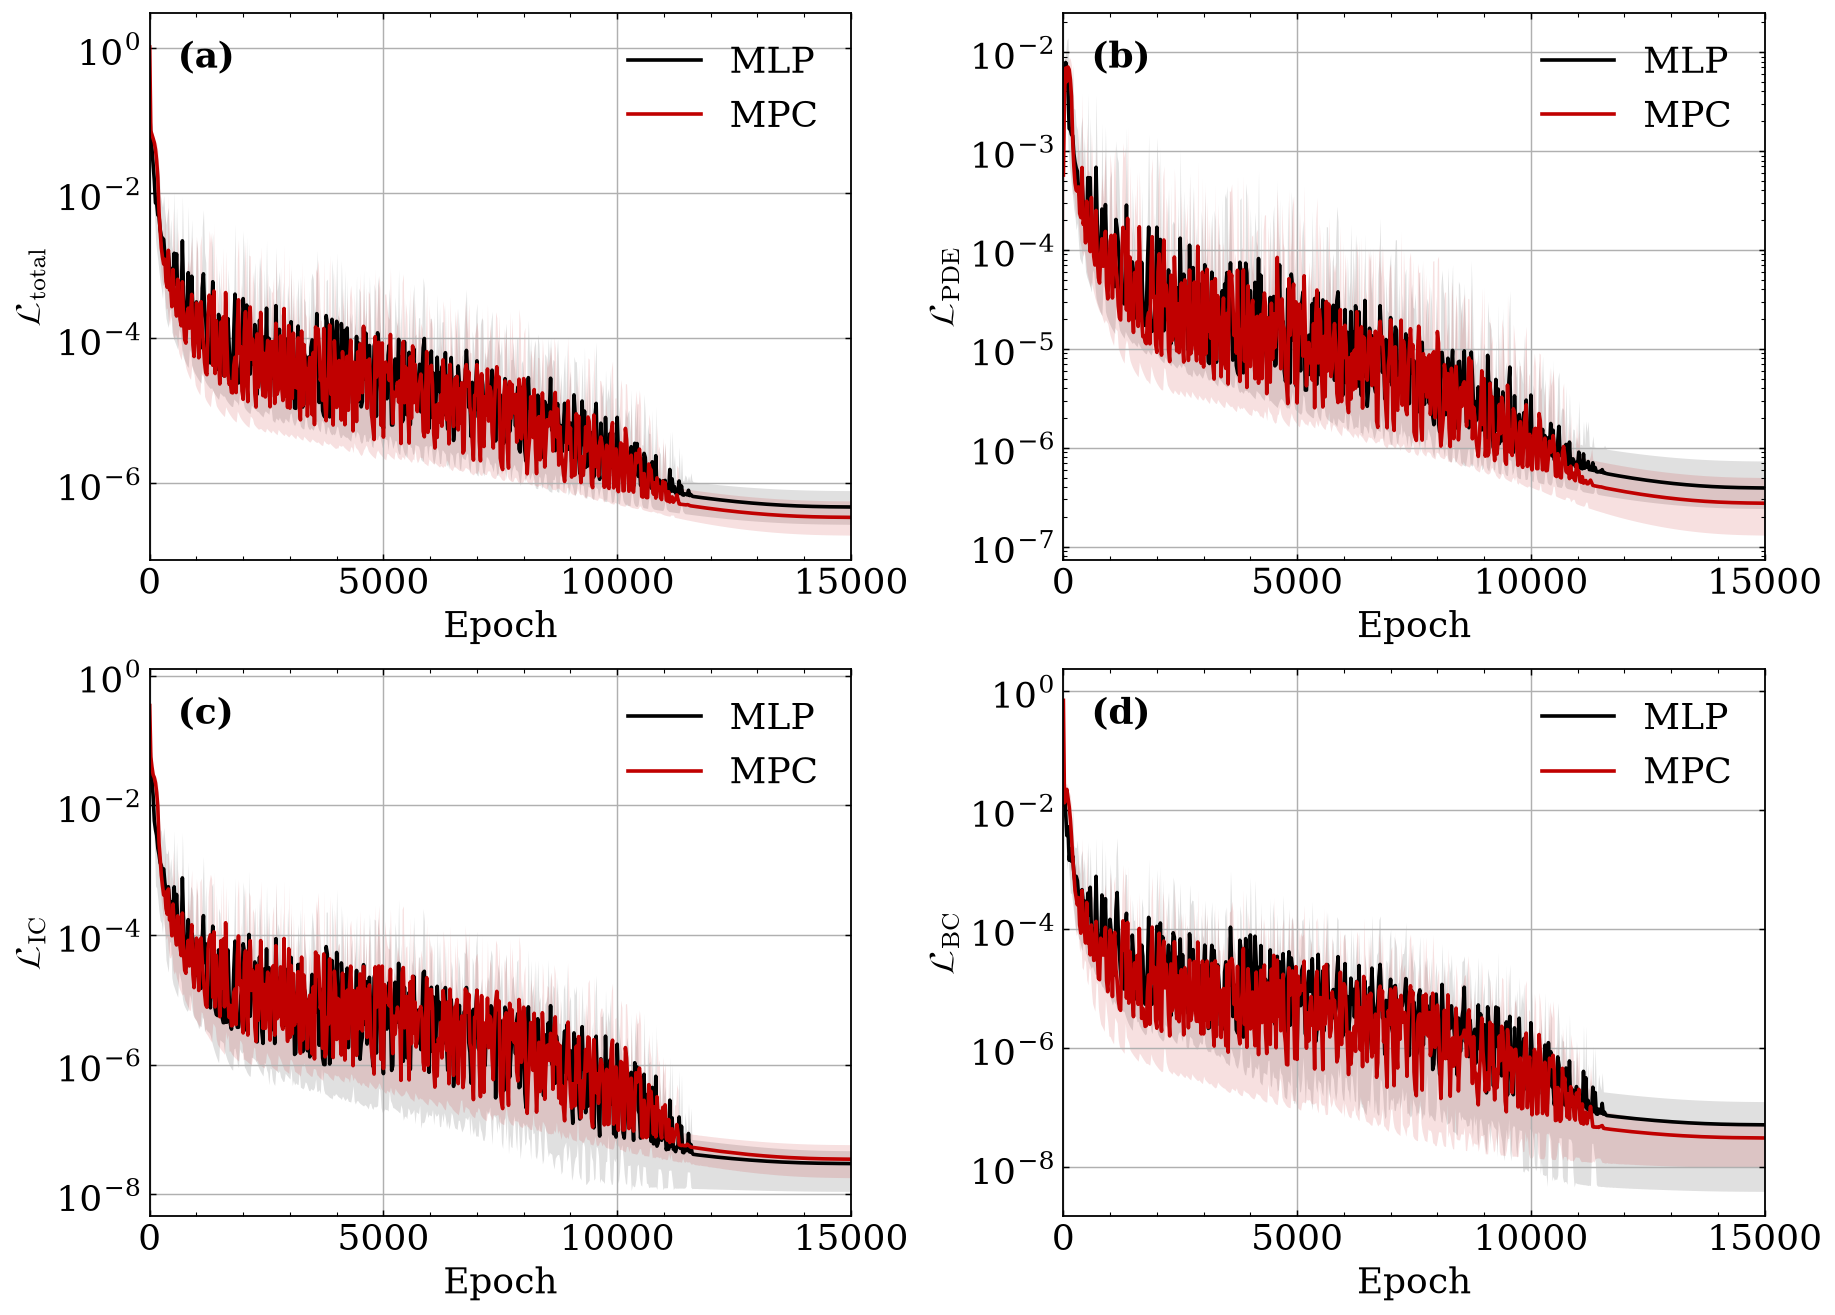

In [42]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    constrained_layout=True
)

componentes = [
    ("train_mse", r"$\mathcal{L}_{\mathrm{total}}$"),
    ("loss_pde", r"$\mathcal{L}_{\mathrm{PDE}}$"),
    ("loss_ic", r"$\mathcal{L}_{\mathrm{IC}}$"),
    ("loss_bc", r"$\mathcal{L}_{\mathrm{BC}}$"),
]

letras = ["(a)", "(b)", "(c)", "(d)"]

for ax, (coluna, ylabel), letra in zip(
    axes.flat, componentes, letras
):

    plot_media_intervalo(
        ax,
        coluna,
        "",
        ylabel
    )

    # Identificação do painel
    ax.text(
        0.04, 0.95,
        letra,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="top",
        ha="left"
    )

    # Eixos
    ax.set_xlim(0, 15000)
    ax.set_xticks([0, 5000, 10000, 15000])

    ax.set_xlabel("Epoch", fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)

    ax.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=True,
        right=True,
        labelsize=20
    )

    # Legenda
    ax.legend(
        fontsize=20,
        frameon=False,
        loc="best"
    )

    ax.set_title("")
    ax.grid(True)
plt.savefig("../paper/figs/loss_main.png", dpi=300, bbox_inches="tight")
plt.show()

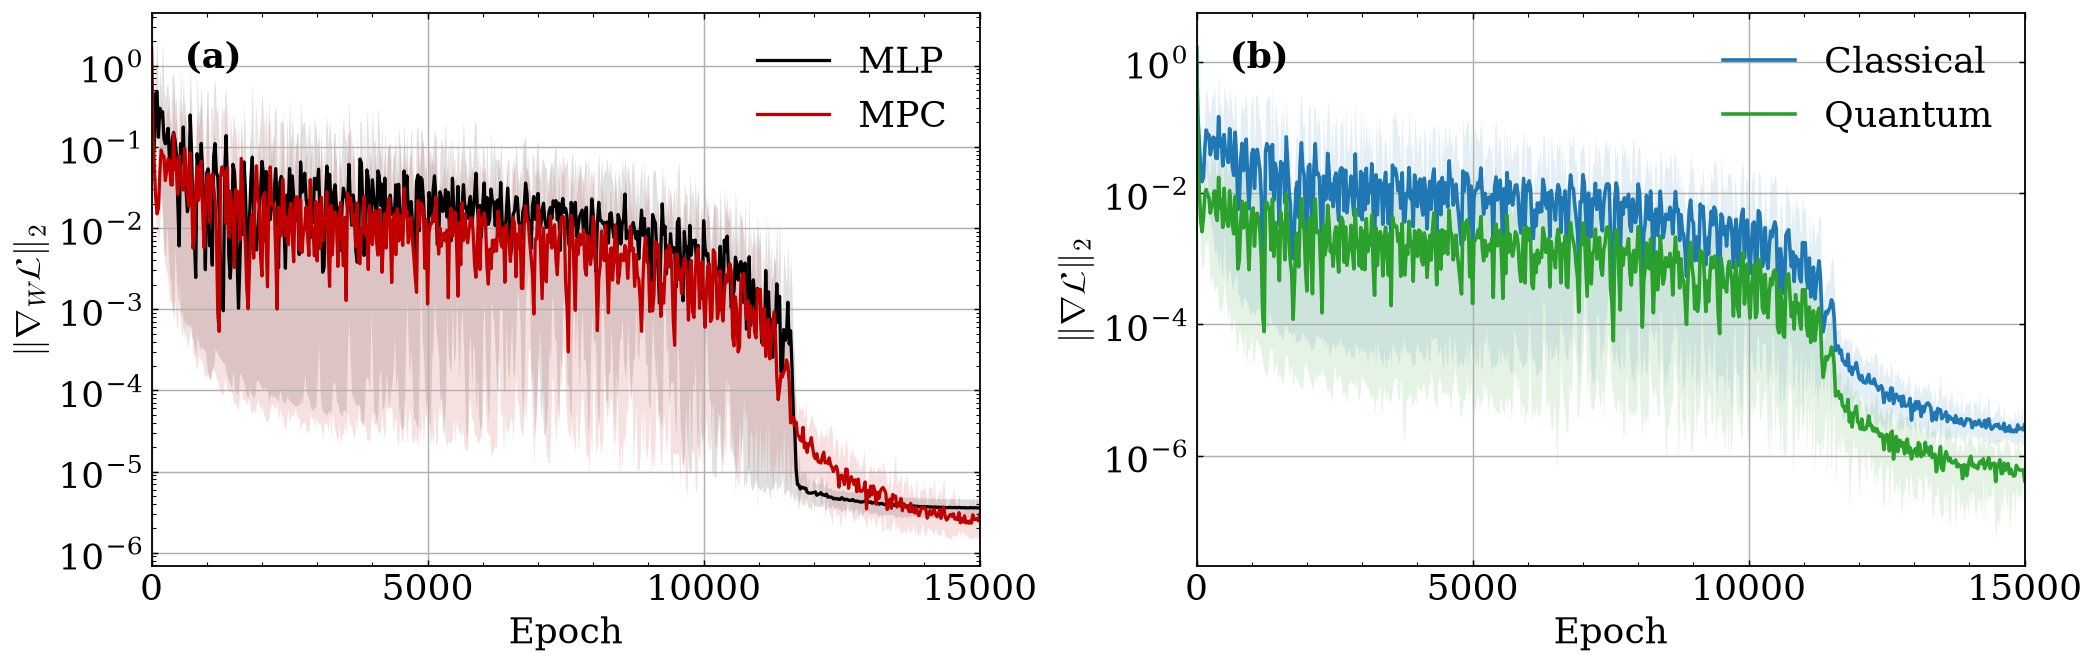

In [51]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    constrained_layout=True
)

# ==================================================
# (a) Gradientes clássicos: MLP vs MPC
# ==================================================

for modelo in ["MLP", "MPC"]:
    dados = (
        historicos[historicos["modelo"] == modelo]
        .groupby("epoch")["grad_classical"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    axes[0].plot(
        dados["epoch"],
        dados["mean"],
        color=CORES[modelo],
        linewidth=1.8,
        label=modelo
    )

    axes[0].fill_between(
        dados["epoch"],
        dados["min"],
        dados["max"],
        color=CORES[modelo],
        alpha=0.12,
        linewidth=0
    )

axes[0].text(
    0.04, 0.95,
    "(a)",
    transform=axes[0].transAxes,
    fontsize=20,
    fontweight="bold",
    va="top",
    ha="left"
)

axes[0].set_xlim(0, 15000)
axes[0].set_xticks([0, 5000, 10000, 15000])
axes[0].set_xlabel("Epoch", fontsize=20)
axes[0].set_ylabel(r"$\|\nabla_{W}\mathcal{L}\|_2$", fontsize=20)
axes[0].set_yscale("log")
axes[0].legend(fontsize=20, frameon=False, loc="best")
axes[0].tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=20
)
axes[0].grid(False)

# ==================================================
# (b) Gradientes do MPC: clássico vs quântico
# ==================================================

gradientes = {
    "Classical": ("grad_classical", "tab:blue"),
    "Quantum": ("grad_quantum", "tab:green"),
}

for nome, (coluna, cor) in gradientes.items():
    dados = (
        hist_mpc.groupby("epoch")[coluna]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    axes[1].plot(
        dados["epoch"],
        dados["mean"],
        color=cor,
        linewidth=2.0,
        label=nome
    )

    axes[1].fill_between(
        dados["epoch"],
        dados["min"],
        dados["max"],
        color=cor,
        alpha=0.12,
        linewidth=0
    )

axes[1].text(
    0.04, 0.95,
    "(b)",
    transform=axes[1].transAxes,
    fontsize=20,
    fontweight="bold",
    va="top",
    ha="left"
)

axes[1].set_xlim(0, 15000)
axes[1].set_xticks([0, 5000, 10000, 15000])
axes[1].set_xlabel("Epoch", fontsize=20)
axes[1].set_ylabel(r"$\|\nabla \mathcal{L}\|_2$", fontsize=20)
axes[1].set_yscale("log")
axes[1].legend(fontsize=20, frameon=False, loc="best")
axes[1].tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=20
)
axes[0].grid(True)
axes[1].grid(True)


plt.savefig("../paper/figs/gradients_main.png", dpi=300, bbox_inches="tight")
plt.show()

In [54]:
metricas_mlp["modelo"] = "MLP"
metricas_mpc["modelo"] = "MPC"

metricas = pd.concat(
    [metricas_mlp, metricas_mpc],
    ignore_index=True
)

resumo = (
    metricas.groupby("modelo")
    .agg(
        sementes=("seed", "nunique"),
        rmse_medio=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        mae_medio=("mae", "mean"),
        l2_relativo=("relative_l2", "mean"),
        parametros=("parameters", "first"),
    )
    .reset_index()
)

display(
    resumo.style.format({
        "rmse_medio": "{:.3e}",
        "rmse_std": "{:.3e}",
        "mae_medio": "{:.3e}",
        "l2_relativo": "{:.3e}",
    })
)

,modelo,sementes,rmse_medio,rmse_std,mae_medio,l2_relativo,parametros
0,MLP,10,9.326e-05,4.683e-05,5.310e-05,4.213e-04,3297
1,MPC,10,6.618e-05,1.141e-05,3.972e-05,2.989e-04,3459


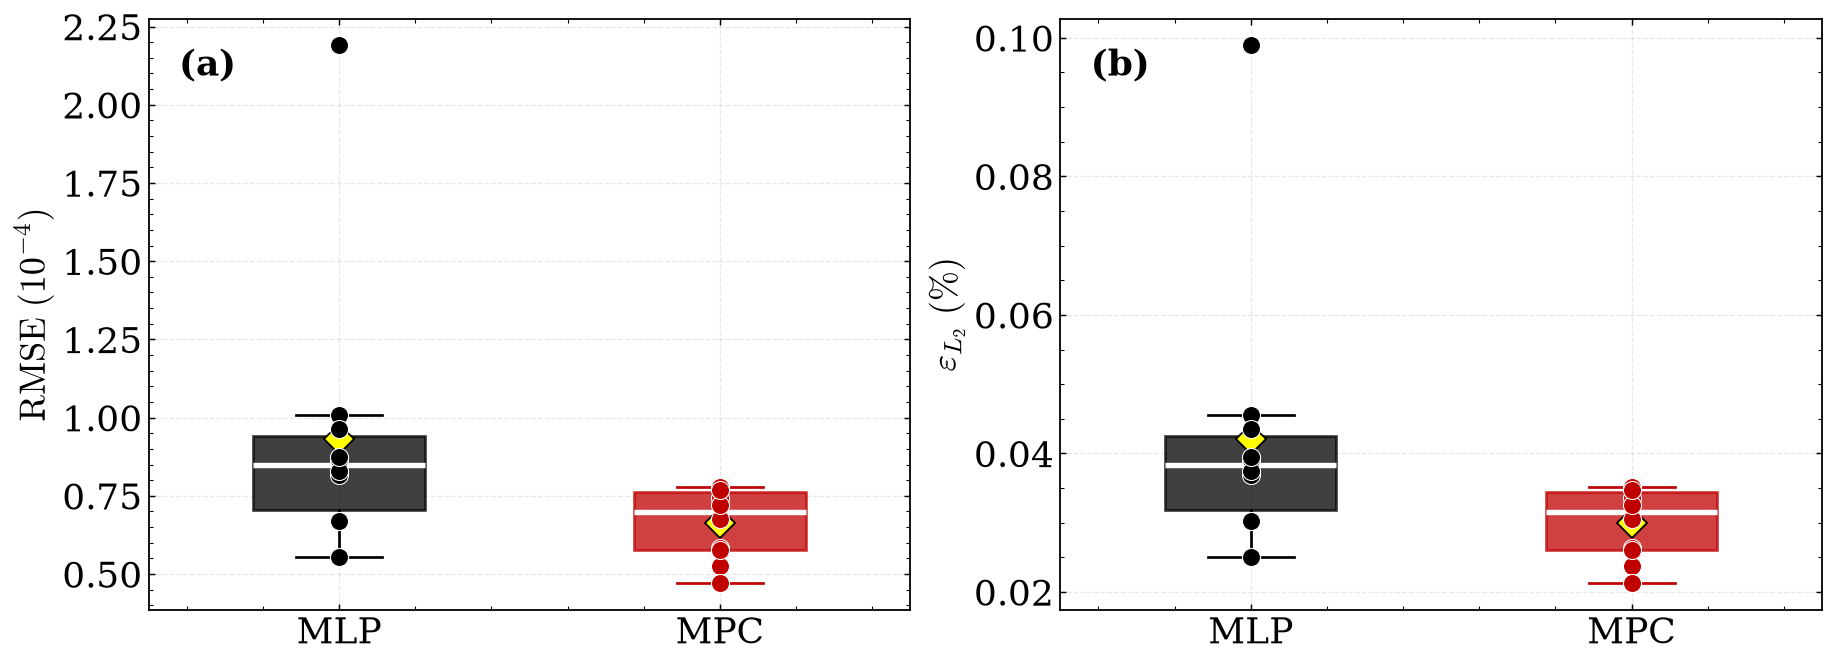

In [67]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

configuracoes = [
    ("rmse", r"$\mathrm{RMSE}\;(10^{-4})$", 1e4),
    ("relative_l2", r"$\varepsilon_{L_2}\;(\%)$", 100),
]

letras = ["(a)", "(b)"]
modelos = ["MLP", "MPC"]

for ax, (coluna, ylabel, fator), letra in zip(
    axes, configuracoes, letras
):

    valores = [
        metricas.loc[
            metricas["modelo"] == modelo, coluna
        ].to_numpy() * fator
        for modelo in modelos
    ]

    bp = ax.boxplot(
        valores,
        positions=[1, 2],
        widths=0.45,
        patch_artist=True,
        showfliers=False,
        whiskerprops=dict(linewidth=1.5),
        capprops=dict(linewidth=1.5),
        showmeans=True,
        meanprops=dict(
            marker="D",
            markerfacecolor="yellow",
            markeredgecolor="black",
            markersize=12
        ),
        medianprops=dict(
            color="white",
            linewidth=3
        ),
    )

    for i, modelo in enumerate(modelos):
        cor = CORES[modelo]

        bp["boxes"][i].set(
            facecolor=cor,
            edgecolor=cor,
            alpha=0.75,
            linewidth=1.5
        )

        bp["whiskers"][2*i].set_color(cor)
        bp["whiskers"][2*i+1].set_color(cor)
        bp["caps"][2*i].set_color(cor)
        bp["caps"][2*i+1].set_color(cor)

        # Valores individuais das sementes
        ax.scatter(
            np.full(len(valores[i]), i + 1),
            valores[i],
            color=cor,
            edgecolor="white",
            linewidth=0.6,
            s=100,
            zorder=3
        )

    ax.text(
        0.04, 0.95,
        letra,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(modelos, fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)

    ax.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=True,
        right=True,
        labelsize=20
    )

    ax.grid(
        True,
        which="major",
        linestyle="--",
        linewidth=0.7,
        alpha=0.3
    )

    ax.set_axisbelow(True)

plt.savefig("../paper/figs/metrics_main.png", dpi=300, bbox_inches="tight")
plt.show()

,modelo,sementes,rmse_medio,rmse_std,mae_medio,l2_relativo,parametros
0,MLP,10,9.326e-05,4.683e-05,5.310e-05,4.213e-04,3297
1,MPC,10,6.618e-05,1.141e-05,3.972e-05,2.989e-04,3459


In [41]:
from pathlib import Path
import json
import pandas as pd

# Caminho dos experimentos
BASE = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")
PASTA_WIDTH = BASE / "mlp_width_2708"

# Parâmetros das MLPs: 2 entradas, 4 camadas ocultas, 1 saída
PARAMETROS_WIDTH = {
    249: 8,
    881: 16,
    3297: 32,
    12737: 64,
    50049: 128,
}

# Carregar resultados
registros = []

for arquivo in sorted(PASTA_WIDTH.rglob("metrics.json")):
    with open(arquivo) as f:
        m = json.load(f)

    m["seed"] = int(arquivo.parent.name.split("_")[-1])
    m["width"] = PARAMETROS_WIDTH[int(m["parameters"])]

    registros.append(m)

df_width = pd.DataFrame(registros)

# Agrupar por largura
tabela_width = (
    df_width.groupby("width", as_index=False)
    .agg(
        sementes=("seed", "nunique"),
        parametros=("parameters", "first"),
        val_mse_media=("best_val_mse", "mean"),
        val_mse_std=("best_val_mse", "std"),
        rmse_medio=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        mae_medio=("mae", "mean"),
        l2_relativo_medio=("relative_l2", "mean"),
    )
    .sort_values("rmse_medio")
    .reset_index(drop=True)
)

print("Ranking das MLPs clássicas — 4 camadas ocultas")

display(
    tabela_width.style.format({
        "parametros": "{:,.0f}",
        "val_mse_media": "{:.3e}",
        "val_mse_std": "{:.3e}",
        "rmse_medio": "{:.3e}",
        "rmse_std": "{:.3e}",
        "mae_medio": "{:.3e}",
        "l2_relativo_medio": "{:.3e}",
    })
)

Ranking das MLPs clássicas — 4 camadas ocultas


,width,sementes,parametros,val_mse_media,val_mse_std,rmse_medio,rmse_std,mae_medio,l2_relativo_medio
0,128,10,"50,049",3.209e-09,3.385e-09,5.741e-05,2.502e-05,2.763e-05,2.593e-04
1,64,10,"12,737",4.298e-09,5.383e-09,6.403e-05,3.080e-05,3.244e-05,2.892e-04
2,32,10,"3,297",9.383e-09,1.240e-08,9.326e-05,4.683e-05,5.310e-05,4.213e-04
3,16,10,881,3.532e-08,2.030e-08,1.863e-04,5.512e-05,1.053e-04,8.416e-04
4,8,10,249,9.946e-08,3.848e-08,3.267e-04,7.209e-05,2.110e-04,1.476e-03
